# TP Olist, demi-journée 1 : comprendre, nettoyer, segmenter

Dans ce notebook, je comprends les données Olist (un site de vente en ligne brésilien), je repère ce qui ne va pas, puis je les nettoie et je les prépare pour le dashboard. Je suis les étapes du TP :

| Étape du TP | Dans ce notebook | Statut |
|---|---|---|
| **Étape 1** : l'environnement (PostgreSQL, JupyterLab) et `client_geo` | vérification de la connexion | ✅ |
| **Étape 2** : comprendre le jeu Olist | chargement, colonnes, liens entre les tables | ✅ |
| **Étape 3** : l'audit de qualité | valeurs manquantes, doublons, dates, cohérence, valeurs aberrantes | ✅ |
| **Étape 4** : les règles de nettoyage, en module réutilisable | médaillon bronze → silver → gold, `src/nettoyage.py`, `src/agregations.py`, `src/pipeline.py` | ✅ |
| **Étape 5** : choisir les données finales | schéma SQL, chargement dans PostgreSQL, modèle en étoile | en cours |
| **Étape 6** : les indicateurs par client | `indicateurs_clients` (RFM + indicateurs pour le clustering) | ✅ |
| **Étape 7** : le clustering | KMeans (k = 4), `segments_clients` | ✅ |

Mes décisions et leurs justifications sont dans `CARNET.md`.

# Étape 1 : l'environnement

PostgreSQL et JupyterLab tournent dans Docker (`docker-compose.yml`). Depuis ce notebook, PostgreSQL s'appelle `postgres` (le nom du service) ; l'adresse de connexion est dans la variable d'environnement `DATABASE_URL`. Je vérifie que la table `client_geo` est bien chargée :

In [1]:
import os
import pandas as pd

pd.read_sql("SELECT count(*) AS lignes, count(DISTINCT customer_id) AS clients FROM client_geo",
            os.environ["DATABASE_URL"])

,lignes,clients
0,99441,99441


# Étape 2 : comprendre le jeu Olist

## 2.1 Chargement des 9 fichiers

Je lis les 9 CSV avec `pd.read_csv`. Pour les colonnes qui contiennent des dates, j'utilise `parse_dates` : sinon pandas les lit comme du texte et je ne peux pas les comparer entre elles.

In [2]:
import pandas as pd
from pathlib import Path

pd.set_option("display.max_columns", 50)   # pour voir toutes les colonnes
DATA = Path("/workspace/donnees/olist")    # dossier où sont les CSV

def lire(nom, dates=None):
    return pd.read_csv(DATA / nom, parse_dates=dates)

customers   = lire("olist_customers_dataset.csv")
geo         = lire("olist_geolocation_dataset.csv")
items       = lire("olist_order_items_dataset.csv", ["shipping_limit_date"])
payments    = lire("olist_order_payments_dataset.csv")
reviews     = lire("olist_order_reviews_dataset.csv", ["review_creation_date", "review_answer_timestamp"])
orders      = lire("olist_orders_dataset.csv", ["order_purchase_timestamp", "order_approved_at",
                                                "order_delivered_carrier_date", "order_delivered_customer_date",
                                                "order_estimated_delivery_date"])
products    = lire("olist_products_dataset.csv")
sellers     = lire("olist_sellers_dataset.csv")
translation = lire("product_category_name_translation.csv")

# Je range tout dans un dictionnaire pour pouvoir faire des boucles sur les 9 tables
tables = {"customers": customers, "geolocation": geo, "order_items": items, "order_payments": payments,
          "order_reviews": reviews, "orders": orders, "products": products,
          "sellers": sellers, "translation": translation}

## 2.2 Taille et colonnes de chaque fichier

In [3]:
pd.DataFrame({nom: {"lignes": len(df), "colonnes": df.shape[1],
                    "liste des colonnes": ", ".join(df.columns)}
              for nom, df in tables.items()}).T

,lignes,colonnes,liste des colonnes
customers,99441,5,"customer_id, customer_unique_id, customer_zip_..."
geolocation,1000163,5,"geolocation_zip_code_prefix, geolocation_lat, ..."
order_items,112650,7,"order_id, order_item_id, product_id, seller_id..."
order_payments,103886,5,"order_id, payment_sequential, payment_type, pa..."
order_reviews,99224,7,"review_id, order_id, review_score, review_comm..."
orders,99441,8,"order_id, customer_id, order_status, order_pur..."
products,32951,9,"product_id, product_category_name, product_nam..."
sellers,3095,4,"seller_id, seller_zip_code_prefix, seller_city..."
translation,71,2,"product_category_name, product_category_name_e..."


Je regarde à quoi ressemble la table principale, `orders` :

In [4]:
orders.head(3)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04


## 2.3 Comment les tables sont reliées

En lisant les noms de colonnes, je vois que certaines reviennent dans plusieurs fichiers (`order_id`, `customer_id`, `product_id`…). Ce sont les **clés** qui relient les tables. J'ai fait ce schéma :

```
customers ──customer_id── orders ──order_id── order_items ──product_id── products ──category── translation
    │                        │                     └──seller_id── sellers
    └─zip_code_prefix─┐      ├──order_id── order_payments
                      │      └──order_id── order_reviews
                  geolocation (zip_code_prefix)
```

La table au centre, c'est `orders` (les commandes).

Ensuite je vérifie, pour chaque clé, s'il y a **une seule ligne** par valeur ou **plusieurs**. Par exemple : est-ce qu'une commande apparaît une seule fois dans `order_items`, ou plusieurs fois ?

In [5]:
def verifier_cle(nom, df, col):
    return {"table": nom, "clé": col,
            "valeurs différentes": df[col].nunique(), "lignes": len(df),
            "résultat": "une ligne par clé" if df[col].is_unique else "plusieurs lignes par clé"}

pd.DataFrame([
    verifier_cle("orders", orders, "order_id"),
    verifier_cle("orders", orders, "customer_id"),
    verifier_cle("customers", customers, "customer_id"),
    verifier_cle("customers", customers, "customer_unique_id"),
    verifier_cle("order_items", items, "order_id"),
    verifier_cle("order_payments", payments, "order_id"),
    verifier_cle("order_reviews", reviews, "order_id"),
    verifier_cle("products", products, "product_id"),
    verifier_cle("sellers", sellers, "seller_id"),
    verifier_cle("geolocation", geo, "geolocation_zip_code_prefix"),
])

,table,clé,valeurs différentes,lignes,résultat
0,orders,order_id,99441,99441,une ligne par clé
1,orders,customer_id,99441,99441,une ligne par clé
2,customers,customer_id,99441,99441,une ligne par clé
3,customers,customer_unique_id,96096,99441,plusieurs lignes par clé
4,order_items,order_id,98666,112650,plusieurs lignes par clé
5,order_payments,order_id,99440,103886,plusieurs lignes par clé
6,order_reviews,order_id,98673,99224,plusieurs lignes par clé
7,products,product_id,32951,32951,une ligne par clé
8,sellers,seller_id,3095,3095,une ligne par clé
9,geolocation,geolocation_zip_code_prefix,19015,1000163,plusieurs lignes par clé


Ce que j'en retiens :
- Il y a autant de `customer_id` que de commandes. En fait, un nouveau `customer_id` est créé **à chaque commande**. Pour retrouver une même personne qui commande plusieurs fois, il faut utiliser `customer_unique_id`.
- `order_items`, `order_payments`, `order_reviews` et `geolocation` ont **plusieurs lignes pour une même clé**. Si je les fusionne directement avec `orders`, des commandes vont se retrouver en double. Il faudra d'abord les regrouper (étape 4, partie 4.3).

# Étape 3 : l'audit de qualité

L'idée de cette étape : **avant de nettoyer, je mesure**. Je compte les problèmes, mais je ne touche pas encore aux données.

Je cherche 5 types de problèmes :
1. les valeurs manquantes
2. les doublons
3. les dates incohérentes
4. les incohérences entre fichiers
5. les valeurs aberrantes

Pour ne rien oublier, je note chaque problème trouvé dans une liste `audit` avec une petite fonction `note()`. À la fin (2.6), j'affiche tout dans un seul tableau.

In [6]:
audit = []

def note(fichier, famille, probleme, n, total):
    """Ajoute un problème à la liste et renvoie le nombre de lignes concernées."""
    audit.append({"fichier": fichier, "famille": famille, "problème": probleme,
                  "lignes": int(n), "%": round(100 * n / total, 2)})
    return int(n)

## 3.1 Valeurs manquantes

J'utilise `isna().sum()` qui compte les cases vides dans chaque colonne.

In [7]:
for nom, df in tables.items():
    for col, n in df.isna().sum().items():
        if n > 0:
            note(nom, "Valeurs manquantes", f"{col} vide", n, len(df))

pd.DataFrame([a for a in audit if a["famille"] == "Valeurs manquantes"])

,fichier,famille,problème,lignes,%
0,order_reviews,Valeurs manquantes,review_comment_title vide,87656,88.34
1,order_reviews,Valeurs manquantes,review_comment_message vide,58247,58.70
2,orders,Valeurs manquantes,order_approved_at vide,160,0.16
3,orders,Valeurs manquantes,order_delivered_carrier_date vide,1783,1.79
4,orders,Valeurs manquantes,order_delivered_customer_date vide,2965,2.98
5,products,Valeurs manquantes,product_category_name vide,610,1.85
6,products,Valeurs manquantes,product_name_lenght vide,610,1.85
7,products,Valeurs manquantes,product_description_lenght vide,610,1.85
8,products,Valeurs manquantes,product_photos_qty vide,610,1.85
9,products,Valeurs manquantes,product_weight_g vide,2,0.01


Dans `orders`, il manque des dates de livraison. Je me demande si c'est normal : une commande annulée ou pas encore livrée n'a logiquement pas de date de livraison. Je vérifie en croisant avec le statut :

In [8]:
pd.crosstab(orders.order_status, orders.order_delivered_customer_date.isna(),
            colnames=["date de livraison vide ?"])

date de livraison vide ?,False,True
order_status,,
approved,0,2
canceled,6,619
created,0,5
delivered,96470,8
invoiced,0,314
processing,0,301
shipped,0,1107
unavailable,0,609


## 3.2 Doublons

Je cherche deux sortes de doublons :
- les lignes **complètement identiques** (avec `duplicated()`),
- les **identifiants qui devraient être uniques** mais qui apparaissent plusieurs fois.

In [9]:
# Lignes identiques dans chaque table
for nom, df in tables.items():
    n = df.duplicated().sum()
    if n > 0:
        note(nom, "Doublons", "lignes complètement identiques", n, len(df))

# Identifiants répétés
note("order_reviews", "Doublons", "review_id qui apparaît plusieurs fois", reviews.review_id.duplicated().sum(), len(reviews))
note("order_reviews", "Doublons", "commande avec plusieurs avis", reviews.order_id.duplicated().sum(), len(reviews))
note("geolocation", "Doublons", "code postal avec plusieurs coordonnées GPS",
     geo.drop_duplicates().geolocation_zip_code_prefix.duplicated().sum(), len(geo))

pd.DataFrame([a for a in audit if a["famille"] == "Doublons"])

,fichier,famille,problème,lignes,%
0,geolocation,Doublons,lignes complètement identiques,261831,26.18
1,order_reviews,Doublons,review_id qui apparaît plusieurs fois,814,0.82
2,order_reviews,Doublons,commande avec plusieurs avis,551,0.56
3,geolocation,Doublons,code postal avec plusieurs coordonnées GPS,719317,71.92


## 3.3 Cohérence temporelle

Une commande suit normalement cet ordre :

**achat → validation du paiement → remise au transporteur → livraison au client**

Donc une date ne devrait jamais être avant la précédente. Je compte les commandes où ce n'est pas le cas.

Remarque : quand une des deux dates est vide, la comparaison donne `False`, donc ces lignes ne sont pas comptées comme des erreurs.

In [10]:
o = orders   # nom plus court

regles = {
    "validation avant l'achat":         o.order_approved_at < o.order_purchase_timestamp,
    "transporteur avant la validation": o.order_delivered_carrier_date < o.order_approved_at,
    "transporteur avant l'achat":       o.order_delivered_carrier_date < o.order_purchase_timestamp,
    "livraison avant le transporteur":  o.order_delivered_customer_date < o.order_delivered_carrier_date,
    "livraison avant l'achat":          o.order_delivered_customer_date < o.order_purchase_timestamp,
    "livraison prévue avant l'achat":   o.order_estimated_delivery_date < o.order_purchase_timestamp,
}
for probleme, erreurs in regles.items():
    note("orders", "Cohérence temporelle", probleme, erreurs.sum(), len(o))

# Pour les avis : on ne peut pas répondre à un avis avant qu'il soit créé
note("order_reviews", "Cohérence temporelle", "réponse avant la création de l'avis",
     (reviews.review_answer_timestamp < reviews.review_creation_date).sum(), len(reviews))

pd.DataFrame([a for a in audit if a["famille"] == "Cohérence temporelle"])

,fichier,famille,problème,lignes,%
0,orders,Cohérence temporelle,validation avant l'achat,0,0.00
1,orders,Cohérence temporelle,transporteur avant la validation,1359,1.37
2,orders,Cohérence temporelle,transporteur avant l'achat,166,0.17
3,orders,Cohérence temporelle,livraison avant le transporteur,23,0.02
4,orders,Cohérence temporelle,livraison avant l'achat,0,0.00
5,orders,Cohérence temporelle,livraison prévue avant l'achat,0,0.00
6,order_reviews,Cohérence temporelle,réponse avant la création de l'avis,0,0.00


Je regarde aussi sur quelle période vont les données, et combien il y a de commandes par mois. S'il y a très peu de commandes au début ou à la fin, c'est sûrement que ces mois ne sont pas complets.

In [11]:
print("Première commande :", o.order_purchase_timestamp.min())
print("Dernière commande :", o.order_purchase_timestamp.max())
o.order_purchase_timestamp.dt.to_period("M").value_counts().sort_index()

Première commande : 2016-09-04 21:15:19
Dernière commande : 2018-10-17 17:30:18


order_purchase_timestamp
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M, Name: count, dtype: int64

## 3.4 Cohérence entre les fichiers

Si un `order_id` est dans `order_items`, il devrait aussi exister dans `orders`. Sinon, l'article appartient à une commande « fantôme ». J'appelle ça des **orphelins**.

Pour les trouver, j'utilise `isin()` : il me dit si chaque valeur existe dans l'autre table.

In [12]:
def orphelins(fichier, probleme, enfant, col_enfant, parent, col_parent):
    absents = ~enfant[col_enfant].isin(parent[col_parent])   
    return note(fichier, "Cohérence entre fichiers", probleme, absents.sum(), len(enfant))

orphelins("order_items",    "order_id inconnu dans orders",          items, "order_id", orders, "order_id")
orphelins("order_payments", "order_id inconnu dans orders",          payments, "order_id", orders, "order_id")
orphelins("order_reviews",  "order_id inconnu dans orders",          reviews, "order_id", orders, "order_id")
orphelins("orders",         "customer_id inconnu dans customers",    orders, "customer_id", customers, "customer_id")
orphelins("order_items",    "product_id inconnu dans products",      items, "product_id", products, "product_id")
orphelins("order_items",    "seller_id inconnu dans sellers",        items, "seller_id", sellers, "seller_id")
orphelins("customers",      "code postal inconnu dans geolocation",  customers, "customer_zip_code_prefix", geo, "geolocation_zip_code_prefix")
orphelins("sellers",        "code postal inconnu dans geolocation",  sellers, "seller_zip_code_prefix", geo, "geolocation_zip_code_prefix")

# Dans l'autre sens : des commandes sans rien derrière
orphelins("orders", "commande sans aucun article", orders, "order_id", items, "order_id")
orphelins("orders", "commande sans paiement",      orders, "order_id", payments, "order_id")
orphelins("orders", "commande sans avis",          orders, "order_id", reviews, "order_id")

# Catégories de produits qui n'ont pas de traduction
categories = products.product_category_name.dropna()
note("products", "Cohérence entre fichiers", "catégorie sans traduction",
     (~categories.isin(translation.product_category_name)).sum(), len(products))
print("Catégories sans traduction :", set(categories) - set(translation.product_category_name))

Catégories sans traduction : {'portateis_cozinha_e_preparadores_de_alimentos', 'pc_gamer'}


Deux autres vérifications :
- est-ce que le **statut** de la commande correspond à ses dates ? (une commande « livrée » doit avoir une date de livraison)
- est-ce que le **montant payé** correspond bien au prix des articles + les frais de port ?

In [13]:
note("orders", "Cohérence entre fichiers", "statut 'delivered' mais pas de date de livraison",
     ((o.order_status == "delivered") & o.order_delivered_customer_date.isna()).sum(), len(o))
note("orders", "Cohérence entre fichiers", "statut 'canceled' mais une date de livraison",
     ((o.order_status == "canceled") & o.order_delivered_customer_date.notna()).sum(), len(o))

# Total des articles (prix + port) par commande, comparé au total payé
total_articles = items.groupby("order_id")[["price", "freight_value"]].sum().sum(axis=1)
total_paye     = payments.groupby("order_id").payment_value.sum()
ecart = (total_paye - total_articles).dropna().abs()

note("order_payments", "Cohérence entre fichiers", "montant payé différent de prix + port (écart > 1 R$)",
     (ecart > 1).sum(), len(ecart))
ecart[ecart > 1].describe()

count    249.000000
mean      13.101727
std       18.310444
min        1.010000
25%        3.960000
50%        7.790000
75%       14.990000
max      182.810000
dtype: float64

## 3.5 Valeurs aberrantes

Une valeur aberrante, c'est une valeur impossible (un prix négatif, un poids de 0 g…) ou très éloignée des autres.

Je commence par `describe()`, qui donne le minimum, le maximum, la moyenne et les quartiles de chaque colonne. Ça permet de repérer rapidement les valeurs bizarres.

In [14]:
items[["price", "freight_value"]].describe()

,price,freight_value
count,112650.000000,112650.000000
mean,120.653739,19.990320
std,183.633928,15.806405
min,0.850000,0.000000
25%,39.900000,13.080000
50%,74.990000,16.260000
75%,134.900000,21.150000
max,6735.000000,409.680000


In [15]:
payments[["payment_value", "payment_installments"]].describe()

,payment_value,payment_installments
count,103886.000000,103886.000000
mean,154.100380,2.853349
std,217.494064,2.687051
min,0.000000,0.000000
25%,56.790000,1.000000
50%,100.000000,1.000000
75%,171.837500,4.000000
max,13664.080000,24.000000


In [16]:
products.select_dtypes("number").describe()

,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
count,32341.000000,32341.000000,32341.000000,32949.000000,32949.000000,32949.000000,32949.000000
mean,48.476949,771.495285,2.188986,2276.472488,30.815078,16.937661,23.196728
std,10.245741,635.115225,1.736766,4282.038731,16.914458,13.637554,12.079047
min,5.000000,4.000000,1.000000,0.000000,7.000000,2.000000,6.000000
25%,42.000000,339.000000,1.000000,300.000000,18.000000,8.000000,15.000000
50%,51.000000,595.000000,1.000000,700.000000,25.000000,13.000000,20.000000
75%,57.000000,972.000000,3.000000,1900.000000,38.000000,21.000000,30.000000
max,76.000000,3992.000000,20.000000,40425.000000,105.000000,105.000000,118.000000


Pour les colonnes de texte, j'utilise `value_counts()` pour voir toutes les valeurs possibles :

In [17]:
payments.payment_type.value_counts()

payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64

Je compte maintenant les valeurs qui me semblent impossibles :

In [18]:
note("order_items",    "Valeurs aberrantes", "prix ≤ 0",                         (items.price <= 0).sum(), len(items))
note("order_items",    "Valeurs aberrantes", "frais de port = 0",                (items.freight_value == 0).sum(), len(items))
note("order_payments", "Valeurs aberrantes", "paiement de 0",                    (payments.payment_value == 0).sum(), len(payments))
note("order_payments", "Valeurs aberrantes", "paiement en 0 fois",               (payments.payment_installments == 0).sum(), len(payments))
note("order_payments", "Valeurs aberrantes", "type de paiement 'not_defined'",   (payments.payment_type == "not_defined").sum(), len(payments))
note("products",       "Valeurs aberrantes", "poids de 0 g",                     (products.product_weight_g == 0).sum(), len(products))

# Le Brésil est à peu près entre -34 et 6 de latitude, et entre -74 et -34 de longitude
hors_bresil = ~geo.geolocation_lat.between(-34, 6) | ~geo.geolocation_lng.between(-74, -34)
note("geolocation", "Valeurs aberrantes", "coordonnées GPS en dehors du Brésil", hors_bresil.sum(), len(geo))

42

Pour les valeurs **très grandes**, j'utilise la méthode de l'écart interquartile (IQR) vue en stats :
- Q1 = la valeur sous laquelle se trouvent 25 % des données, Q3 = celle sous laquelle se trouvent 75 %
- IQR = Q3 − Q1
- une valeur est considérée comme extrême si elle dépasse **Q3 + 1,5 × IQR**

Attention : extrême ne veut pas dire faux. Un frigo coûte plus cher qu'un stylo, c'est normal.

In [19]:
def valeurs_extremes(fichier, df, col):
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    seuil = q3 + 1.5 * (q3 - q1)
    n = note(fichier, "Valeurs aberrantes", f"{col} > {seuil:.0f} (méthode IQR)", (df[col] > seuil).sum(), len(df))
    print(f"{col} : {n} valeurs au-dessus de {seuil:.1f} (le max est {df[col].max()})")

valeurs_extremes("order_items", items, "price")
valeurs_extremes("order_items", items, "freight_value")
valeurs_extremes("order_payments", payments, "payment_value")
valeurs_extremes("products", products, "product_weight_g")

price : 8427 valeurs au-dessus de 277.4 (le max est 6735.0)
freight_value : 11613 valeurs au-dessus de 33.3 (le max est 409.68)
payment_value : 7981 valeurs au-dessus de 344.4 (le max est 13664.08)
product_weight_g : 4551 valeurs au-dessus de 4300.0 (le max est 40425.0)


Dernière chose : les noms de villes. J'ai l'impression qu'une même ville peut être écrite de plusieurs façons (avec ou sans accent, en majuscules…). Je compare le nombre de villes avant et après avoir tout mis en minuscules sans accents :

In [20]:
villes = geo.geolocation_city
villes_simplifiees = (villes.str.lower()
                      .str.normalize("NFKD").str.encode("ascii", "ignore").str.decode("ascii"))
print("Nombre de villes différentes           :", villes.nunique())
print("Après minuscules et sans les accents  :", villes_simplifiees.nunique())

Nombre de villes différentes           : 8011
Après minuscules et sans les accents  : 5968


## 3.6 Bilan de l'audit

Voici tous les problèmes trouvés, rangés par fichier. Je m'en sers pour décider quoi nettoyer et pour remplir `CARNET.md`.

In [21]:
bilan = (pd.DataFrame(audit)
         .query("lignes > 0")                      # je garde seulement les vrais problèmes
         .sort_values(["fichier", "famille", "lignes"], ascending=[True, True, False])
         .reset_index(drop=True))
bilan

,fichier,famille,problème,lignes,%
0,customers,Cohérence entre fichiers,code postal inconnu dans geolocation,278,0.28
1,geolocation,Doublons,code postal avec plusieurs coordonnées GPS,719317,71.92
2,geolocation,Doublons,lignes complètement identiques,261831,26.18
3,geolocation,Valeurs aberrantes,coordonnées GPS en dehors du Brésil,42,0.00
4,order_items,Valeurs aberrantes,freight_value > 33 (méthode IQR),11613,10.31
5,order_items,Valeurs aberrantes,price > 277 (méthode IQR),8427,7.48
6,order_items,Valeurs aberrantes,frais de port = 0,383,0.34
7,order_payments,Cohérence entre fichiers,montant payé différent de prix + port (écart >...,249,0.25
8,order_payments,Valeurs aberrantes,payment_value > 344 (méthode IQR),7981,7.68
9,order_payments,Valeurs aberrantes,paiement de 0,9,0.01


Le même bilan résumé : combien de problèmes de chaque type par fichier.

In [22]:
bilan.pivot_table(index="fichier", columns="famille", values="lignes", aggfunc="count", fill_value=0)

famille,Cohérence entre fichiers,Cohérence temporelle,Doublons,Valeurs aberrantes,Valeurs manquantes
fichier,,,,,
customers,1,0,0,0,0
geolocation,0,0,2,1,0
order_items,0,0,0,3,0
order_payments,1,0,0,4,0
order_reviews,0,0,2,0,2
orders,5,3,0,0,3
products,1,0,0,2,8
sellers,1,0,0,0,0


# Étape 4 : les règles de nettoyage, en module réutilisable

## 4.1 Architecture médaillon : bronze → silver → gold

Je range le traitement en trois couches, chacune avec un rôle précis :

| Couche | Contenu | Code | Dans PostgreSQL (étape 5) |
|---|---|---|---|
| 🥉 **bronze** | les 9 CSV **bruts**, tels quels | `pd.read_csv` (partie 2.1) | schéma `bronze` |
| 🥈 **silver** | les tables **nettoyées** (mêmes lignes, types corrigés) + les **lignes rejetées** avec leur raison | `src/nettoyage.py` | schéma `silver` + tables `rejets_<table>` |
| 🥇 **gold** | les tables **prêtes à l'usage** : `commandes`, `vendeurs`, `produits` (puis le modèle en étoile, `indicateurs_clients`, `segments_clients`) | `src/agregations.py` | schéma `gold` |

Pourquoi :
- on garde toujours le **brut** : si une règle de nettoyage est fausse, on la corrige et on recalcule, sans retélécharger ;
- chaque couche ne lit **que la couche d'avant** : on sait d'où vient chaque chiffre du dashboard ;
- Airflow fera exactement le même chemin avec les CSV de la boutique : bronze (fichier reçu) → silver (`nettoyage.py`) → gold (`agregations.py`).

Les règles sont dans des **modules Python** et pas dans le notebook : une fonction par table, qui renvoie `(propre, rejets)`, sans lire ni écrire de fichier. Elles sont testées avec `pytest` (`tests/`).

In [23]:
# src/ est dans le PYTHONPATH du conteneur (docker-compose.yml) : on importe les modules directement.
# autoreload : si je modifie nettoyage.py ou agregations.py, le notebook prend la nouvelle version sans redémarrer.
%load_ext autoreload
%autoreload 2

import os
import nettoyage, agregations

## 4.2 Silver : les règles de nettoyage (`src/nettoyage.py`)

Chaque fonction applique les règles de la table, convertit les types (dates en UTC depuis l'heure de São Paulo, montants au centime, codes postaux sur 5 chiffres) et met de côté les lignes rejetées avec la raison. Le détail de chaque règle et sa justification sont dans `CARNET.md` (partie 4).

In [24]:
silver, rejets = {}, {}
silver["traductions"], rejets["traductions"] = nettoyage.nettoyer_traductions(translation)
silver["commandes"],   rejets["commandes"]   = nettoyage.nettoyer_commandes(orders)
silver["clients"],     rejets["clients"]     = nettoyage.nettoyer_clients(customers)
silver["articles"],    rejets["articles"]    = nettoyage.nettoyer_articles(items)
silver["paiements"],   rejets["paiements"]   = nettoyage.nettoyer_paiements(payments)
silver["avis"],        rejets["avis"]        = nettoyage.nettoyer_avis(reviews)
silver["produits"],    rejets["produits"]    = nettoyage.nettoyer_produits(products, silver["traductions"])
silver["vendeurs"],    rejets["vendeurs"]    = nettoyage.nettoyer_vendeurs(sellers)
silver["geolocalisation"], rejets["geolocalisation"] = nettoyage.nettoyer_geolocalisation(geo)

# Bilan : combien de lignes gardées et rejetées, et pourquoi
pd.DataFrame([{"table": nom, "lignes bronze": len(silver[nom]) + len(rejets[nom]),
               "lignes silver": len(silver[nom]), "rejetées": len(rejets[nom]),
               "raisons": rejets[nom].raison_rejet.value_counts().to_dict() if len(rejets[nom]) else ""}
              for nom in silver])

,table,lignes bronze,lignes silver,rejetées,raisons
0,traductions,74,74,0,
1,commandes,99441,99441,0,
2,clients,99441,99441,0,
3,articles,112650,112650,0,
4,paiements,103886,103883,3,{'moyen de paiement inconnu': 3}
5,avis,99224,99224,0,
6,produits,32951,32951,0,
7,vendeurs,3095,3095,0,
8,geolocalisation,1000163,720461,279702,"{'ligne en double': 279660, 'coordonnées hors ..."


Quelques vérifications sur ce que le nettoyage a changé :

In [25]:
s = silver
print("Code postal avant / après     :", customers.customer_zip_code_prefix.iloc[1], "->", s["clients"].customer_zip_code_prefix.iloc[1])
print("Date d'achat avant / après    :", orders.order_purchase_timestamp.iloc[0], "->", s["commandes"].order_purchase_timestamp.iloc[0])
print("Commandes aux dates incohérentes (marquées, gardées) :", s["commandes"].dates_incoherentes.sum())
print("Catégories ajoutées à la traduction :", sorted(set(silver["traductions"].product_category_name) - set(translation.product_category_name)))
print("Paiements en 0 fois corrigés  :", (payments.payment_installments == 0).sum(), "-> 1 fois")

# Idempotence : nettoyer des données déjà propres ne change rien
propre2, rejets2 = nettoyage.nettoyer_commandes(s["commandes"])
pd.testing.assert_frame_equal(propre2, s["commandes"]); assert len(rejets2) == 0
print("Nettoyer deux fois ne change rien : OK")

Code postal avant / après     : 9790 -> 09790
Date d'achat avant / après    : 2017-10-02 10:56:33 -> 2017-10-02 13:56:33+00:00
Commandes aux dates incohérentes (marquées, gardées) : 1382
Catégories ajoutées à la traduction : ['inconnue', 'pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos']
Paiements en 0 fois corrigés  : 2 -> 1 fois
Nettoyer deux fois ne change rien : OK


## 4.3 Gold : les regroupements pour le dashboard (`src/agregations.py`)

Pour choisir ce que je garde, je me pose une question pour chaque CSV : **qu'est-ce que l'administrateur veut lire sur le dashboard ?** (combien, comment, à quelle vitesse, avec quelle satisfaction, où). Les tables qui ont plusieurs lignes par commande sont **résumées** avec `groupby()` + `agg()` : je ne supprime rien, je résume.

### 4.3.1 orders : délais, période, marqueurs

Pas d'agrégation (déjà une ligne par commande), mais des colonnes calculées : délai réel, **délai promis**, retard, détail des étapes (validation, préparation, transport), mois / jour / heure d'achat **à l'heure locale**, statut en français. Les délais des commandes aux dates incohérentes sont vidés pour ne pas fausser les moyennes.

In [26]:
commandes_enrichies = agregations.enrichir_commandes(s["commandes"])
commandes_enrichies[["delai_livraison_jours", "delai_promis_jours", "retard_jours", "delai_validation_heures",
                     "delai_preparation_jours", "delai_transport_jours"]].describe().round(1)

,delai_livraison_jours,delai_promis_jours,retard_jours,delai_validation_heures,delai_preparation_jours,delai_transport_jours
count,95103.0,99441.0,95103.0,97899.0,96262.0,95102.0
mean,12.6,23.8,-11.1,9.6,2.9,9.4
std,9.6,8.8,10.2,25.1,3.5,8.8
min,0.5,1.6,-146.0,0.0,0.0,0.0
25%,6.8,18.3,-16.2,0.0,0.9,4.1
50%,10.3,23.2,-11.6,0.0,1.9,7.1
75%,15.8,28.4,-6.4,14.4,3.6,12.1
max,209.6,155.2,189.0,4509.6,125.8,205.2


### 4.3.2 order_items → une ligne par commande

Le panier : nombre d'articles, de produits, de vendeurs et de catégories, montants (produits, port, total), part du port, poids total, et la **catégorie principale** (celle qui pèse le plus en R$).

In [27]:
articles_par_commande = agregations.articles_par_commande(s["articles"], s["produits"])
articles_par_commande.head()

,order_id,nb_articles,nb_produits,nb_vendeurs,nb_categories,montant_produits,frais_port,prix_article_max,poids_total_g,date_limite_expedition,montant_total,part_frais_port,categorie_principale
0,00010242fe8c5a6d1ba2dd792cb16214,1,1,1,1,58.90,13.29,58.90,650.0,2017-09-19 12:45:35+00:00,72.19,0.184,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,1,1,1,1,239.90,19.93,239.90,30000.0,2017-05-03 14:05:13+00:00,259.83,0.077,pet_shop
2,000229ec398224ef6ca0657da4fc703e,1,1,1,1,199.00,17.87,199.00,3050.0,2018-01-18 16:48:30+00:00,216.87,0.082,furniture_decor
3,00024acbcdf0a6daa1e931b038114c75,1,1,1,1,12.99,12.79,12.99,200.0,2018-08-15 13:10:18+00:00,25.78,0.496,perfumery
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,1,1,1,199.90,18.14,199.90,3750.0,2017-02-13 15:57:51+00:00,218.04,0.083,garden_tools


### 4.3.3 order_payments → une ligne par commande

Une commande peut être payée **avec plusieurs moyens** (2 246 commandes, presque toutes carte + bon d'achat). Je garde le **nombre de moyens différents**, puis **une colonne par moyen** avec le nombre de paiements (`pd.crosstab`) et le montant (`pivot_table`), et le **moyen principal** (celui du plus gros montant).

In [28]:
paiements_par_commande = agregations.paiements_par_commande(s["paiements"])
paiements_par_commande[paiements_par_commande.nb_moyens_paiement > 1].head()

,order_id,montant_paye,nb_paiements,nb_moyens_paiement,nb_echeances_max,paye_en_plusieurs_fois,nb_credit_card,nb_boleto,nb_voucher,nb_debit_card,montant_credit_card,montant_boleto,montant_voucher,montant_debit_card,moyen_principal
36,0016dfedd97fc2950e388d2971d718c7,70.55,2,2,5,True,1,0,1,0,52.63,0.0,17.92,0.0,credit_card
215,009ac365164f8e06f59d18a08045f6c4,32.00,6,2,1,False,1,0,5,0,0.88,0.0,31.12,0.0,voucher
257,00b4a910f64f24dbcac04fe54088a443,50.59,2,2,1,False,1,0,1,0,2.54,0.0,48.05,0.0,voucher
273,00bd50cdd31bd22e9081e6e2d5b3577b,85.80,3,2,1,False,1,0,2,0,4.88,0.0,80.92,0.0,voucher
281,00c405bd71187154a7846862f585a9d4,46.69,7,2,1,False,1,0,6,0,6.03,0.0,40.66,0.0,voucher


### 4.3.4 order_reviews → une ligne par commande

Note du dernier avis, pire note, **texte du dernier commentaire** (pour afficher les derniers avis négatifs sur le dashboard), marqueur avis négatif (note ≤ 2), délai de réponse d'Olist à l'avis.

In [29]:
avis_par_commande = agregations.avis_par_commande(s["avis"])
avis_par_commande[avis_par_commande.avis_negatif & avis_par_commande.commentaire.notna()].head()

,order_id,note,note_min,nb_avis,a_laisse_un_commentaire,titre_avis,commentaire,date_avis,delai_reponse_jours,avis_negatif
8,0005a1a1728c9d785b8e2b08b904576c,1,1,1,True,<NA>,Na descrição do produto quando fui efetuar a c...,2018-03-30 03:00:00+00:00,3.0,True
16,000aed2e25dbad2f9ddb70584c5a2ded,1,1,1,True,produto não entregue,Mudo minha opinião assim que receber o produto...,2018-05-19 03:00:00+00:00,3.5,True
24,0010dedd556712d7bb69a19cb7bbd37a,1,1,1,True,<NA>,nao recebi o produto,2017-11-08 02:00:00+00:00,0.5,True
34,00169e31ef4b29deaae414f9a5e95929,1,1,1,True,<NA>,Entrega muito demorada. Ainda não recebi o pro...,2018-01-24 02:00:00+00:00,1.0,True
43,001d8f0e34a38c37f7dba2a37d4eba8b,1,1,1,True,<NA>,Entrega prometida 24/05/17. Dia 26/05/17 não h...,2017-05-26 03:00:00+00:00,0.8,True


### 4.3.5 geolocation et customers : positions

Un point par code postal (médiane) pour placer les **vendeurs**. Pour les **clients**, j'utilise `client_geo` (fournie, une position par `customer_id`).

In [30]:
geo_cp = agregations.geo_par_code_postal(s["geolocalisation"])

client_geo = pd.read_sql("SELECT customer_id, latitude, longitude FROM client_geo", os.environ["DATABASE_URL"])
clients = s["clients"].merge(client_geo, on="customer_id", how="left")
print("Clients sans position :", clients.latitude.isna().sum())
print("Vendeurs sans position :", (~s["vendeurs"].seller_zip_code_prefix.isin(geo_cp.geolocation_zip_code_prefix)).sum())

Clients sans position : 0
Vendeurs sans position : 7


### 4.3.6 Distance entre le client et ses vendeurs

Le prix du port et le délai de livraison dépendent de la distance : je calcule la distance à vol d'oiseau (formule de haversine) entre le client et chacun de ses vendeurs, et je garde la plus grande. Je note aussi si tous les vendeurs sont dans le même État que le client.

In [31]:
positions_clients = (commandes_enrichies[["order_id", "customer_id"]]
                     .merge(clients[["customer_id", "latitude", "longitude", "customer_state"]], on="customer_id")
                     .drop(columns="customer_id"))
positions_vendeurs = (s["vendeurs"]
                      .merge(geo_cp, left_on="seller_zip_code_prefix", right_on="geolocation_zip_code_prefix", how="left")
                      [["seller_id", "lat", "lng", "seller_state"]])
distances = agregations.distance_par_commande(s["articles"], positions_clients, positions_vendeurs)

# Plus le vendeur est loin, plus le port et le délai augmentent ?
avec_distance = commandes_enrichies.merge(distances, on="order_id").merge(articles_par_commande, on="order_id")
avec_distance.groupby(pd.cut(avec_distance.distance_vendeur_km, [0, 100, 500, 1000, 2000, 4000]), observed=True).agg(
    commandes=("order_id", "count"), frais_port_moyen=("frais_port", "mean"),
    delai_moyen_jours=("delai_livraison_jours", "mean")).round(1)

,commandes,frais_port_moyen,delai_moyen_jours
distance_vendeur_km,,,
"(0, 100]",18357,13.4,6.6
"(100, 500]",37658,21.0,11.6
"(500, 1000]",26592,24.2,14.4
"(1000, 2000]",10019,33.2,18.0
"(2000, 4000]",5824,39.8,21.2


### 4.3.7 Table finale `commandes` : une ligne par commande

Je fusionne tout avec `how="left"` pour garder toutes les commandes. J'ajoute l'**écart de paiement** (payé − prix − port, pour vérifier l'hypothèse des intérêts) et le **numéro de la commande pour ce client** (1 = première commande) pour séparer nouveaux clients et clients qui reviennent.

In [32]:
commandes = agregations.table_commandes(commandes_enrichies, clients, articles_par_commande,
                                        paiements_par_commande, avis_par_commande, distances)
print(commandes.shape)

# L'hypothèse des intérêts : les commandes où le client a payé plus ont-elles plus d'échéances ?
commandes.groupby(pd.cut(commandes.ecart_paiement, [-1000, -1, 1, 1000]), observed=True).agg(
    commandes=("order_id", "count"), echeances_moyennes=("nb_echeances_max", "mean")).round(1)

(99441, 68)


,commandes,echeances_moyennes
ecart_paiement,,
"(-1000, -1]",18,2.3
"(-1, 1]",98415,2.9
"(1, 1000]",232,6.6


### 4.3.8 Tables `vendeurs` et `produits`

- **vendeurs** : une ligne par vendeur (chiffre d'affaires, panier moyen, nombre de clients, note moyenne, part d'avis négatifs, part en retard, position). Regroupement en deux temps (vendeur × commande, puis vendeur) pour qu'une commande de 5 articles ne compte pas 5 fois.
- **produits** : une ligne par produit (ventes, **prix médian** = prix du catalogue, note moyenne et nombre d'avis pour les étoiles du catalogue, volume du colis).

In [33]:
vendeurs = agregations.table_vendeurs(s["vendeurs"], s["articles"], s["produits"], commandes,
                                      avis_par_commande, geo_cp)
produits = agregations.table_produits(s["produits"], s["articles"], avis_par_commande)
vendeurs.sort_values("chiffre_affaires", ascending=False).head()

,seller_id,seller_zip_code_prefix,seller_city,seller_state,nb_commandes,nb_clients,nb_articles,chiffre_affaires,panier_moyen,note_moyenne,part_avis_negatifs,part_en_retard,premiere_vente,derniere_vente,nb_categories,lat,lng
2617,4869f7a5dfa277a7dca6462dcf3b52b2,14840,guariba,SP,1132,1124,1156,229472.63,202.71,4.133,0.135,0.115,2017-03-07 15:43:03+00:00,2018-08-24 22:42:51+00:00,10,-21.363908,-48.228772
901,53243585a1d6dc2643021fd1853d8905,42738,lauro de freitas,BA,358,349,410,222776.05,622.28,4.132,0.121,0.043,2017-08-28 21:29:21+00:00,2018-08-21 12:52:32+00:00,2,-12.894841,-38.339100
2463,4a3ca9315b744ce9f8e9374361493884,14940,ibitinga,SP,1806,1792,1987,200472.92,111.00,3.828,0.192,0.111,2017-01-08 11:35:14+00:00,2018-08-27 13:46:11+00:00,7,-21.757538,-48.829262
557,fa1c13f2614d7b5c4749cbc52fecda94,13170,sumare,SP,585,581,586,194042.03,331.70,4.339,0.105,0.103,2017-01-07 22:45:31+00:00,2018-08-29 12:48:09+00:00,5,-22.822130,-47.270791
1182,7c67e1448b00f6e969d365cea6b010ab,08577,itaquaquecetuba,SP,982,971,1364,187923.89,191.37,3.488,0.257,0.100,2017-01-27 00:44:11+00:00,2018-08-07 21:58:53+00:00,6,-23.484621,-46.367008


In [34]:
produits.sort_values("nb_ventes", ascending=False).head()

,product_id,product_category_name,product_name_length,product_description_length,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english,nb_ventes,nb_commandes,prix_median,prix_min,prix_max,chiffre_affaires,frais_port_moyen,note_moyenne,nb_avis,volume_cm3
13430,aca2eb7d00ea1a7b8ebd4e68314663af,moveis_decoracao,44.0,903.0,6.0,2600.0,50.0,10.0,30.0,furniture_decor,527,431,69.9,69.9,109.9,37608.90,13.68,4.1,429,15000.0
9661,99a4788cb24856965c36a24e339b6058,cama_mesa_banho,54.0,245.0,1.0,1383.0,50.0,10.0,40.0,bed_bath_table,488,467,89.9,74.0,89.9,43025.56,16.49,3.91,458,20000.0
14051,422879e10f46682990de24d770e7f83d,ferramentas_jardim,56.0,348.0,2.0,1550.0,30.0,22.0,30.0,garden_tools,484,352,53.9,49.0,59.9,26577.22,15.75,4.14,351,19800.0
30293,389d119b48cf3043d311335e499d9c6b,ferramentas_jardim,59.0,341.0,2.0,1750.0,37.0,22.0,40.0,garden_tools,392,311,53.9,49.0,59.9,21440.59,18.47,4.18,310,32560.0
4598,368c6c730842d78016ad823897a372db,ferramentas_jardim,57.0,366.0,2.0,1650.0,30.0,22.0,30.0,garden_tools,388,291,53.9,49.0,59.9,21056.80,17.85,4.13,289,19800.0


### 4.3.9 Vérifications : les regroupements n'ont rien perdu

Les totaux doivent être **identiques** entre bronze (CSV d'origine) et gold.

In [35]:
montants_moyens = ["montant_" + m for m in agregations.MOYENS]
verifs = pd.DataFrame([
    {"contrôle": "total payé",             "bronze": payments.payment_value.sum(), "gold": commandes.montant_paye.sum()},
    {"contrôle": "total des produits",      "bronze": items.price.sum(),            "gold": commandes.montant_produits.sum()},
    {"contrôle": "total des frais de port", "bronze": items.freight_value.sum(),    "gold": commandes.frais_port.sum()},
    {"contrôle": "nombre d'articles",       "bronze": len(items),                   "gold": commandes.nb_articles.sum()},
    {"contrôle": "nombre de paiements",     "bronze": len(payments),                "gold": commandes.nb_paiements.sum() + len(rejets["paiements"])},
    {"contrôle": "CA des vendeurs",         "bronze": items.price.sum(),            "gold": vendeurs.chiffre_affaires.sum()},
    {"contrôle": "CA des produits",         "bronze": items.price.sum(),            "gold": produits.chiffre_affaires.sum()},
]).round(2)
verifs["identique ?"] = (verifs.bronze - verifs.gold).abs() < 0.01

avec_paiement = commandes.montant_paye.notna()
print("Montants par moyen = montant payé :",
      ((commandes.loc[avec_paiement, montants_moyens].sum(axis=1) - commandes.loc[avec_paiement, "montant_paye"]).abs() < 0.01).all())
verifs

Montants par moyen = montant payé : True


,contrôle,bronze,gold,identique ?
0,total payé,16008872.12,16008872.12,True
1,total des produits,13591643.70,13591643.70,True
2,total des frais de port,2251909.54,2251909.54,True
3,nombre d'articles,112650.00,112650.00,True
4,nombre de paiements,103886.00,103886.00,True
5,CA des vendeurs,13591643.70,13591643.70,True
6,CA des produits,13591643.70,13591643.70,True


### 4.3.10 Récapitulatif : colonnes avant / après

In [36]:
pd.DataFrame([
    {"table gold": "commandes", "vient de": "orders + customers + client_geo + items + payments + reviews",
     "lignes": len(commandes), "colonnes bronze": orders.shape[1] + customers.shape[1] - 1, "colonnes gold": commandes.shape[1]},
    {"table gold": "vendeurs", "vient de": "sellers + items + reviews + geolocation",
     "lignes": len(vendeurs), "colonnes bronze": sellers.shape[1], "colonnes gold": vendeurs.shape[1]},
    {"table gold": "produits", "vient de": "products + translation + items + reviews",
     "lignes": len(produits), "colonnes bronze": products.shape[1], "colonnes gold": produits.shape[1]},
    {"table gold": "geo_par_code_postal", "vient de": "geolocation",
     "lignes": len(geo_cp), "colonnes bronze": geo.shape[1], "colonnes gold": geo_cp.shape[1]},
])

,table gold,vient de,lignes,colonnes bronze,colonnes gold
0,commandes,orders + customers + client_geo + items + paym...,99441,12,68
1,vendeurs,sellers + items + reviews + geolocation,3095,4,17
2,produits,products + translation + items + reviews,32951,9,20
3,geo_par_code_postal,geolocation,19010,5,5


## 4.4 Écrire les couches bronze / silver / gold sur le disque (`src/pipeline.py`)

Les parties 4.2 et 4.3 ont servi à **vérifier** les règles. Ici, je les applique pour de bon : `pipeline.py` enchaîne les trois couches et les enregistre en Parquet (un format qui garde les types, contrairement au CSV).

```
donnees/olist (CSV)  ──►  donnees/bronze  ──►  donnees/silver (+ rejets/)  ──►  donnees/gold
                          tout en texte        nettoyage.py                     agregations.py
```

C'est le même code que celui qu'Airflow utilisera plus tard. On peut aussi le lancer sans le notebook :
`docker compose exec jupyter python src/pipeline.py`.

In [37]:
import pipeline

for nom, couche in pipeline.COUCHES.items():   # bronze, puis silver, puis gold
    print(f"=== {nom} -> {pipeline.DONNEES / nom}")
    display(couche())

=== bronze -> /workspace/donnees/bronze


,table,lignes,colonnes
0,commandes,99441,8
1,clients,99441,5
2,articles,112650,7
3,paiements,103886,5
4,avis,99224,7
5,produits,32951,9
6,vendeurs,3095,4
7,geolocalisation,1000163,5
8,traductions,71,2


=== silver -> /workspace/donnees/silver


,table,bronze,silver,rejetées
0,traductions,71,74,0
1,commandes,99441,99441,0
2,clients,99441,99441,0
3,articles,112650,112650,0
4,paiements,103886,103883,3
5,avis,99224,99224,0
6,produits,32951,32951,0
7,vendeurs,3095,3095,0
8,geolocalisation,1000163,720461,279702


=== gold -> /workspace/donnees/gold


,table,lignes,colonnes
0,commandes,99441,68
1,vendeurs,3095,17
2,produits,32951,20
3,geo_par_code_postal,19010,5
4,indicateurs_clients,94983,15


Je relis une table gold et une table de rejets pour vérifier que les fichiers sont bien écrits et que les types sont conservés :

In [38]:
commandes_gold = pd.read_parquet(pipeline.GOLD / "commandes.parquet")
print(commandes_gold.shape)
print("Date d'achat :", commandes_gold.order_purchase_timestamp.dtype)
print("Code postal  :", commandes_gold.customer_zip_code_prefix.iloc[:3].tolist())

pd.read_parquet(pipeline.SILVER / "rejets" / "rejets_paiements.parquet")

(99441, 68)
Date d'achat : datetime64[us, UTC]
Code postal  : ['69309', '99025', '12244']


,order_id,payment_sequential,payment_type,payment_installments,payment_value,raison_rejet
0,4637ca194b6387e2d538dc89b124b0ee,1,not_defined,1,0.0,moyen de paiement inconnu
1,00b1cb0320190ca0daa2c88b35206009,1,not_defined,1,0.0,moyen de paiement inconnu
2,c8c528189310eaa44a745b8d9d26908b,1,not_defined,1,0.0,moyen de paiement inconnu


# Étape 5 : choisir les données finales

Le tableau des colonnes gardées, les clés et le schéma en étoile sont décrits dans `CARNET.md` (parties 6 et 7). Ici, je **charge** les trois couches dans PostgreSQL avec `src/chargement.py` :

| Fichier | Rôle |
|---|---|
| `sql/schema.sql` | schémas `bronze` et `silver` (types, clés primaires et étrangères) + tables `rejets_<table>` |
| `src/chargement.py` | lit les Parquet de `donnees/` et les copie dans PostgreSQL (`COPY`) |
| `sql/etoile.sql` | dimensions et `fait_ventes`, puis contrôle du chiffre d'affaires |

Le chargement peut être relancé : il vide les tables avant de les remplir, donc pas de doublons.

## 5.1 Bibliothèques nécessaires

Lire les Parquet demande `pyarrow`, et se connecter à PostgreSQL demande `psycopg2`. Si l'image Jupyter n'a pas été reconstruite, elles peuvent manquer : cette cellule les installe seulement si besoin (à refaire après chaque recréation du conteneur, tant que le `Dockerfile` n'est pas à jour).

In [39]:
import importlib.util, subprocess, sys

for module, paquet in [("pyarrow", "pyarrow"), ("psycopg2", "psycopg2-binary")]:
    if importlib.util.find_spec(module) is None:
        print("installation de", paquet)
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", paquet])
    else:
        print(paquet, ": déjà installé")

pyarrow : déjà installé
psycopg2-binary : déjà installé


## 5.2 Chargement bronze → silver → gold → étoile

**L'ordre compte** : `charger_bronze` rejoue `schema.sql`, qui recrée les schémas `bronze` et `silver` vides ; les étapes suivantes les remplissent. L'étoile se charge en dernier, car elle lit silver.

In [40]:
import chargement

with chargement.connexion() as conn:
    for nom, etape in [("bronze", chargement.charger_bronze), ("silver", chargement.charger_silver),
                       ("gold", chargement.charger_gold), ("étoile", chargement.charger_etoile)]:
        print(f"=== {nom}")
        etape(conn)

=== bronze


bronze.traductions                 71 lignes


bronze.clients                  99441 lignes
bronze.vendeurs                  3095 lignes


bronze.produits                 32951 lignes


bronze.commandes                99441 lignes


bronze.articles                112650 lignes


... (14 outputs left out)

gold.commandes                  99441 lignes
gold.vendeurs                    3095 lignes


gold.produits                   32951 lignes
gold.geo_par_code_postal        19010 lignes


gold.indicateurs_clients        94983 lignes
=== étoile


NOTICE:  schema "bronze" already exists, skipping
NOTICE:  schema "silver" already exists, skipping
NOTICE:  schema "gold" already exists, skipping
NOTICE:  drop cascades to 9 other objects
DETAIL:  drop cascades to table bronze.commandes
drop cascades to table bronze.clients
drop cascades to table bronze.articles
drop cascades to table bronze.paiements
drop cascades to table bronze.avis
drop cascades to table bronze.produits
drop cascades to table bronze.vendeurs
drop cascades to table bronze.geolocalisation
drop cascades to table bronze.traductions
NOTICE:  drop cascades to 18 other objects
DETAIL:  drop cascades to table silver.traductions
drop cascades to table silver.clients
drop cascades to table silver.vendeurs
drop cascades to table silver.produits
drop cascades to table silver.commandes
drop cascades to table silver.articles
drop cascades to table silver.paiements
drop cascades to table silver.avis
drop cascades to table silver.geolocalisation
drop cascades to table silver.rej

## 5.3 Vérifications

Le chiffre d'affaires de `fait_ventes` doit être **identique** à celui des articles silver (13 591 643,70 R$ attendu), sinon une jointure duplique ou perd des lignes. `chargement.charger_etoile` s'arrête déjà en erreur dans ce cas ; je le montre ici dans le notebook.

In [41]:
import os

pd.read_sql("""
    SELECT (SELECT sum(prix)  FROM gold.fait_ventes)  AS ca_etoile,
           (SELECT sum(price) FROM silver.articles)   AS ca_silver,
           (SELECT count(*)   FROM gold.fait_ventes)  AS lignes_etoile,
           (SELECT count(*)   FROM silver.articles)   AS lignes_silver,
           (SELECT count(*)   FROM gold.dim_client)   AS personnes,
           (SELECT count(DISTINCT customer_unique_id) FROM silver.clients) AS personnes_silver
""", os.environ["DATABASE_URL"])

,ca_etoile,ca_silver,lignes_etoile,lignes_silver,personnes,personnes_silver
0,13591643.7,13591643.7,112650,112650,96096,96096


Nombre de lignes par table (bronze, silver, rejets, étoile) pour vérifier que rien ne s'est perdu :

In [42]:
tables = ["bronze.commandes", "silver.commandes", "bronze.articles", "silver.articles",
          "bronze.paiements", "silver.paiements", "silver.rejets_paiements",
          "bronze.geolocalisation", "silver.geolocalisation", "silver.rejets_geolocalisation",
          "gold.commandes", "gold.vendeurs", "gold.produits",
          "gold.dim_date", "gold.dim_client", "gold.dim_produit", "gold.dim_vendeur", "gold.fait_ventes"]
requete = " UNION ALL ".join(f"SELECT '{t}' AS table_sql, count(*) AS lignes FROM {t}" for t in tables)
pd.read_sql(requete, os.environ["DATABASE_URL"])

,table_sql,lignes
0,silver.rejets_paiements,3
1,gold.dim_date,852
2,gold.dim_vendeur,3095
3,gold.vendeurs,3095
4,gold.dim_produit,32951
5,gold.produits,32951
6,bronze.paiements,103886
7,silver.paiements,103883
8,silver.commandes,99441
9,gold.fait_ventes,112650


# Étape 6 : les indicateurs par client

Le clustering (étape 7) se fait **par personne**. Je construis `indicateurs_clients` : une ligne par `customer_unique_id`, calculée à partir de la table gold `commandes` par `agregations.indicateurs_clients` (un `groupby`). Le pipeline l'écrit dans `donnees/gold/indicateurs_clients.parquet` ; `src/chargement.py` (étape 5) la charge dans `gold.indicateurs_clients`.

Elle n'est **ni un fait ni une dimension** de l'étoile : c'est une table pour l'apprentissage, reliée à `dim_client` par `customer_unique_id`.

## 6.1 Quelles commandes compter ?
Seulement les **vrais achats** : ni annulée ni indisponible, et avec un montant. Je mesure ce que ça change :

In [43]:
c = pd.read_parquet(pipeline.GOLD / "commandes.parquet")   # la table gold écrite par le pipeline
achats = c[~c.est_annulee & c.montant_total.notna()]
pd.DataFrame({
    "toutes les commandes": [len(c), c.customer_unique_id.nunique(), c.order_purchase_timestamp.max()],
    "vrais achats": [len(achats), achats.customer_unique_id.nunique(), achats.order_purchase_timestamp.max()],
}, index=["commandes", "personnes", "date de référence"])

,toutes les commandes,vrais achats
commandes,99441,98199
personnes,96096,94983
date de référence,2018-10-17 20:30:18+00:00,2018-09-03 12:06:57+00:00


Sans ce filtre, la date de référence serait une commande **annulée** du 17/10/2018 (les 6 dernières commandes du jeu sont annulées) : toutes les récences seraient gonflées d'environ 44 jours, et 676 personnes auraient « dépensé » 0 R$.

## 6.2 La table `indicateurs_clients`

In [44]:
ind = agregations.indicateurs_clients(c)
print(ind.shape, "| une ligne par personne :", ind.customer_unique_id.is_unique)
print("total dépensé =", round(ind.montant_total.sum(), 2), "| vrais achats =", round(achats.montant_total.sum(), 2))
ind.head()

(94983, 15) | une ligne par personne : True
total dépensé = 15735527.03 | vrais achats = 15735527.03


,customer_unique_id,recence_jours,nb_commandes,montant_total,panier_moyen,anciennete_jours,nb_articles,nb_categories_max,note_moyenne,delai_livraison_moyen_jours,part_en_retard,part_paiement_plusieurs_fois,etat,date_premiere_commande,date_derniere_commande
0,0000366f3b9a7992bf8c76cfdf3221e2,115,1,141.90,141.90,115,1,1.0,5.0,6.4,0.0,1.0,SP,2018-05-10 13:56:27+00:00,2018-05-10 13:56:27+00:00
1,0000b849f77a49e4a4ce2b2a4ca5be3f,118,1,27.19,27.19,118,1,1.0,4.0,3.3,0.0,0.0,SP,2018-05-07 14:11:27+00:00,2018-05-07 14:11:27+00:00
2,0000f46a3911fa3c0805444483337064,541,1,86.22,86.22,541,1,1.0,3.0,25.7,0.0,1.0,SC,2017-03-11 00:05:03+00:00,2017-03-11 00:05:03+00:00
3,0000f6ccb0745a6a4b88665a16c9f078,325,1,43.62,43.62,325,1,1.0,4.0,20.0,0.0,1.0,PA,2017-10-12 23:29:41+00:00,2017-10-12 23:29:41+00:00
4,0004aac84e0df4da2b147fca70cf8255,292,1,196.89,196.89,292,1,1.0,5.0,13.1,0.0,1.0,SP,2017-11-14 21:45:42+00:00,2017-11-14 21:45:42+00:00


| Famille | Colonne | Calcul |
|---|---|---|
| **R**écence | `recence_jours` | jours entre la dernière commande et la date de référence |
| **F**réquence | `nb_commandes` | nombre de vrais achats |
| **M**ontant | `montant_total`, `panier_moyen` | produits + port (comme le chiffre d'affaires de l'étoile) |
| Pour l'étape 7 | `anciennete_jours`, `nb_articles`, `nb_categories_max`, `note_moyenne`, `delai_livraison_moyen_jours`, `part_en_retard`, `part_paiement_plusieurs_fois`, `etat` | candidats pour départager les clients |

## 6.3 À quoi ressemblent les indicateurs ?

In [45]:
display(ind.describe().T.round(2))
print("part des personnes avec une seule commande :", round((ind.nb_commandes == 1).mean() * 100, 1), "%")
ind.nb_commandes.value_counts().head(6)

,count,mean,std,min,25%,50%,75%,max
recence_jours,94983.0,242.446606,152.986955,0.0,118.0,223.0,351.0,728.0
nb_commandes,94983.0,1.033859,0.210811,1.0,1.0,1.0,1.0,16.0
montant_total,94983.0,165.666772,226.726478,9.59,63.1,107.9,182.93,13664.08
panier_moyen,94983.0,160.726969,219.88783,9.59,62.41,105.74,176.965,13664.08
anciennete_jours,94983.0,245.115989,153.486271,4.0,121.0,227.0,355.0,728.0
nb_articles,94983.0,1.180222,0.620593,1.0,1.0,1.0,1.0,24.0
nb_categories_max,94983.0,1.008412,0.093383,1.0,1.0,1.0,1.0,3.0
note_moyenne,94299.0,4.113863,1.316621,1.0,4.0,5.0,5.0,5.0
delai_livraison_moyen_jours,92039.0,12.628392,9.572433,0.5,6.8,10.3,15.8,209.6
part_en_retard,92039.0,0.081687,0.272392,0.0,0.0,0.0,0.0,1.0


part des personnes avec une seule commande : 97.0 %


nb_commandes
1    92096
2     2651
3      188
4       29
5        9
6        5
Name: count, dtype: int64

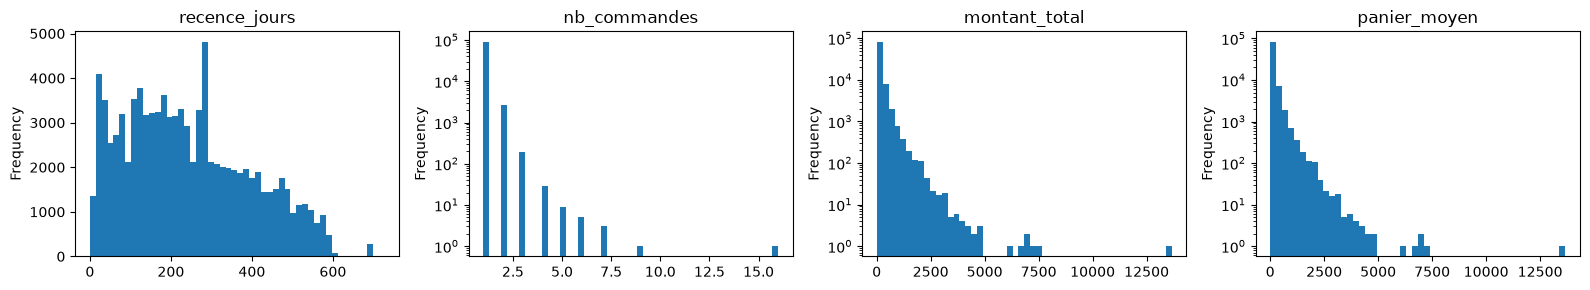

In [46]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 4, figsize=(16, 3))
for ax, col in zip(axes, ["recence_jours", "nb_commandes", "montant_total", "panier_moyen"]):
    ind[col].plot.hist(bins=50, ax=ax, title=col, log=(col != "recence_jours"))
plt.tight_layout()

**Ce que j'en retiens pour l'étape 7 :**
- **97 % des personnes n'ont commandé qu'une fois** : la fréquence ne départage presque personne. Le RFM seul ne suffira pas, d'où les indicateurs en plus (note, retard, paiement en plusieurs fois).
- `montant_total` et `panier_moyen` sont **très asymétriques** (médiane ~106 R$, maximum 13 664 R$) : il faudra les passer au logarithme avant de standardiser, sinon quelques gros clients écraseront tout.
- `part_en_retard` est vide pour les personnes dont rien n'a encore été livré, et `note_moyenne` pour celles sans avis : imputation par la médiane à l'étape 7.

# Étape 7 : le clustering

**But** : ranger les 94 983 personnes dans quelques groupes qui se ressemblent, pour que le marketing traite chaque groupe différemment (relancer les endormis, récompenser les fidèles, rattraper les insatisfaits).

Le code est dans `src/clustering.py` (et non dans ce notebook) pour qu'Airflow le réutilise. Il se lance une fois avec :

```
docker compose exec jupyter python src/clustering.py
```

Il entraîne le modèle, l'enregistre dans `modeles/` et écrit le segment de chaque personne dans `gold.segments_clients` et `gold.dim_client`. **Ici, je relis seulement le résultat** : ce notebook ne réentraîne rien et n'écrit rien en base.

## 7.1 Les indicateurs retenus et leur transformation

| Variable | Pourquoi | Transformation |
|---|---|---|
| `recence_jours` | **R** : depuis quand la personne n'a pas acheté | — |
| `nb_commandes` | **F** : fréquence | `log1p` |
| `montant_total` | **M** : montant dépensé | `log1p` |
| `note_moyenne` | satisfaction | — |
| `delai_livraison_moyen_jours` | logistique | `log1p` |

- `panier_moyen` n'est **pas** retenu : avec 97 % de personnes à une seule commande, il est presque égal à `montant_total` et doublerait le poids du montant.
- Les trous (684 notes, 2 944 délais) sont remplis par la **médiane**, puis tout est **standardisé** : KMeans compare des distances, une variable en centaines de jours ne doit pas écraser une note sur 5.

In [ ]:
import clustering as cl
import pandas as pd
import matplotlib.pyplot as plt

prep, kmeans, noms, meta = cl.charger_modele("v1")
print("variables :", meta["variables"])
print("modèle entraîné le", meta["date_entrainement"][:19], "| k =", meta["k"], "| silhouette =", meta["silhouette"])

## 7.2 Choix de k

KMeans pour k = 2 à 10. Deux mesures :
- l'**inertie** (somme des distances au centre du groupe) baisse toujours quand k augmente : on cherche le « coude » ;
- la **silhouette** (entre -1 et 1) dit si chaque personne est plus proche de son groupe que des autres. Elle est calculée sur le **même échantillon** de 10 000 personnes pour tous les k, sinon les scores ne sont pas comparables.

In [ ]:
scores = pd.DataFrame(meta["scores"])
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.5))
a1.plot(scores.k, scores.inertie, marker="o"); a1.set(title="Inertie (méthode du coude)", xlabel="k")
a2.plot(scores.k, scores.silhouette, marker="o"); a2.set(title="Silhouette", xlabel="k")
for a in (a1, a2):
    a.axvline(meta["k"], color="red", linestyle="--")
plt.tight_layout()
scores.round(3)

**k retenu : 4.** La silhouette est meilleure pour k = 2 ou 3, mais 2-3 groupes sont trop pauvres pour le marketing : je prends la meilleure silhouette **entre 4 et 8**, et la courbe d'inertie s'infléchit aussi vers 4-5. Une silhouette d'environ 0,25 veut dire que les groupes se chevauchent : normal pour des clients qui ont presque tous acheté une seule fois.

## 7.3 Description des segments

In [ ]:
from IPython.display import display

ind = cl.lire_indicateurs(cl.connexion())
seg = cl.attribuer_segments(ind, prep, kmeans, noms)
display(cl.profils(ind, seg))

centres = pd.DataFrame(kmeans.cluster_centers_, columns=cl.VARIABLES,
                       index=[noms[i] for i in range(len(noms))])
print("Centres standardisés (0 = moyenne de tous les clients, en écarts-types) :")
display(centres.round(2).style.background_gradient(cmap="RdBu_r", vmin=-2, vmax=2, axis=None))

Chaque nom vient du trait le plus éloigné de la moyenne (`nommer_segments`), relu sur les profils :

| Segment | Part | Qui c'est | Décision |
|---|---|---|---|
| **récents** | 41 % | achat il y a environ 4 mois, livrés en 8 jours, contents | les faire revenir tant qu'ils se souviennent de la boutique |
| **endormis** | 40 % | contents, mais plus d'achat depuis environ un an | campagne de réactivation |
| **insatisfaits** | 17 % | note de 1,6 et livraisons **2,5 fois plus longues** (21 j contre 8 j) | le problème est la livraison : à régler avec transporteurs et vendeurs |
| **fidèles** | 3 % | les seuls avec plusieurs commandes, panier double | programme de fidélité |

Le petit segment « fidèles » est un **résultat**, pas un bug : 97 % des clients Olist n'ont acheté qu'une fois.

In [ ]:
seg.segment.value_counts().plot.barh(title="Nombre de personnes par segment", figsize=(7, 2.5))
plt.gca().invert_yaxis();

## 7.4 Enregistrement et vérification en base

- `modeles/standardisation_v1.joblib` (médianes, logarithme, standardisation), `modeles/kmeans_v1.joblib`, `modeles/segments_v1.json` (k, scores, noms, date) ;
- `gold.segments_clients` : une ligne par personne, avec la version du modèle et la date ;
- `gold.dim_client.segment` en **SCD 2** : si le segment d'un client change, l'ancienne ligne est fermée et une nouvelle est ouverte, et les ventes passées gardent l'ancien segment.

Pour Airflow (demi-journée 3) : `charger_modele` puis `attribuer_segments` sur les seuls clients touchés, sans réentraîner. Les 1 113 personnes sans vrai achat n'ont pas de segment.

In [ ]:
pd.read_sql("""
    SELECT coalesce(segment, '(aucun : pas de vrai achat)') AS segment, count(*) AS personnes
    FROM gold.dim_client WHERE est_courant
    GROUP BY 1 ORDER BY 2 DESC
""", os.environ["DATABASE_URL"])